In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SQL = ROOT / "sql"
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

load_dotenv(ROOT / ".env")
engine = create_engine(os.environ["DATABASE_URL"])


def run_sql(name):
    return pd.read_sql((SQL / f"{name}.sql").read_text(), engine)


run_sql("portfolio_overview")

,loans,funded_billions,judged_loans,default_rate_pct,avg_int_rate_pct,first_issued,last_issued
0,2260668,34.0,779026,15.19,13.09,2007-06-01,2018-12-01


In [2]:
by_grade = run_sql("default_rate_by_grade")
by_grade

,grade,loans,default_rate_pct,avg_int_rate_pct,loss_rate_pct,net_return_pct
0,A,167117,5.5,7.1,2.4,7.1
1,B,252072,11.6,10.8,5.7,8.9
2,C,207469,18.7,14.0,10.1,9.6
3,D,100456,24.5,17.3,14.6,9.5
4,E,37456,30.4,20.2,19.4,11.6
5,F,11912,35.3,23.4,23.7,14.2
6,G,2544,38.9,24.8,25.8,13.7


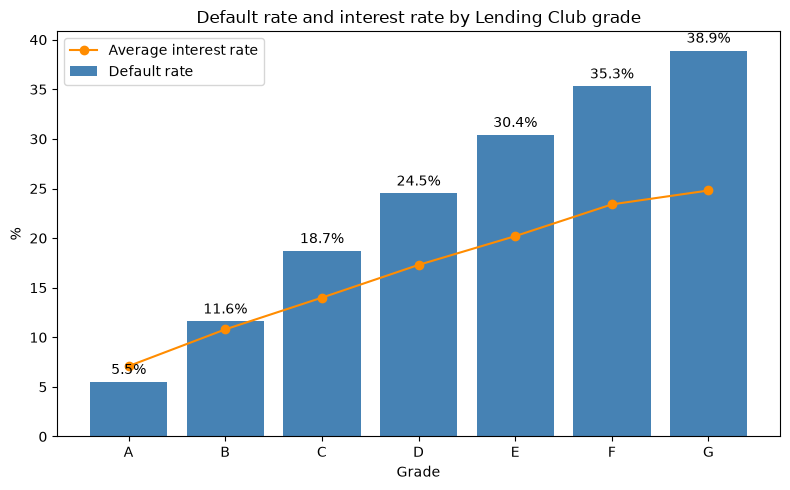

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(by_grade["grade"], by_grade["default_rate_pct"], color="steelblue", label="Default rate")
ax.plot(by_grade["grade"], by_grade["avg_int_rate_pct"], color="darkorange", marker="o", label="Average interest rate")
for i, value in enumerate(by_grade["default_rate_pct"]):
    ax.text(i, value + 0.8, f"{value}%", ha="center")
ax.set_title("Default rate and interest rate by Lending Club grade")
ax.set_xlabel("Grade")
ax.set_ylabel("%")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(IMAGES / "default_rate_by_grade.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding: grade
Lending Club's grades rank risk well. Default rates climb steadily from 5.5% for grade A to 38.9% for
grade G, and interest rates rise with them (7.1% to 24.8%). On average the extra interest more than
covered the extra losses: lifetime net return grows from 7.1% for A to about 14% for F and G. Returns
are lifetime totals, not annualized, and lower grades hold more 60-month loans that earn interest for
longer, so the gap per year is smaller than it looks.

In [4]:
vintages = run_sql("vintage_default_rates")
vintages.pivot(index="issue_year", columns="term", values=["judged_loans", "default_rate_pct"])

judged_loans          default_rate_pct      
term                 36       60               36    60
issue_year                                             
2007              603.0      NaN             26.2   NaN
2008             2393.0      NaN             20.7   NaN
2009             5281.0      NaN             13.7   NaN
2010             9156.0   3381.0             10.9  22.4
2011            14101.0   7620.0             10.6  23.6
2012            43470.0   9897.0             13.6  27.7
2013           100422.0  34382.0             12.3  25.1
2014           162570.0  12939.0             13.7  26.0
2015           283026.0      0.0             14.9   NaN
2016            89785.0      0.0             16.1   NaN
2017                0.0      0.0              NaN   NaN
2018                0.0      0.0              NaN   NaN

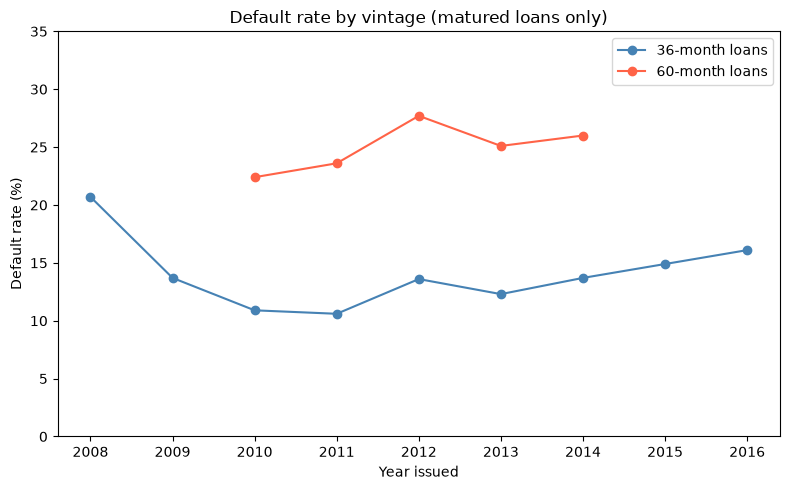

In [5]:
judged_vintages = vintages[vintages["judged_loans"] >= 1000]

fig, ax = plt.subplots(figsize=(8, 5))
for term, color in [(36, "steelblue"), (60, "tomato")]:
    rows = judged_vintages[judged_vintages["term"] == term]
    ax.plot(rows["issue_year"], rows["default_rate_pct"], marker="o", color=color, label=f"{term}-month loans")
ax.set_title("Default rate by vintage (matured loans only)")
ax.set_xlabel("Year issued")
ax.set_ylabel("Default rate (%)")
ax.set_ylim(0, 35)
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "default_rate_by_vintage.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding: vintages and term
60-month loans default about twice as often as 36-month loans issued in the same year (22-28% vs.
11-14% for 2010-2014). Default rates bottomed out with the 2010-2011 vintages, when lending standards
were tight after the financial crisis, then crept back up to 16.1% for 2016 as Lending Club grew fast.
Only the earliest part of the 2016 vintage (and of 2014's 60-month loans) has matured, so those points
rest on the loans issued first in the year.

In [6]:
run_sql("default_rate_by_purpose")

,purpose,loans,default_rate_pct,avg_int_rate_pct
0,small_business,9940,24.6,15.5
1,moving,5514,19.7,15.1
2,house,3457,19.2,15.1
3,medical,8576,17.8,13.9
4,other,42605,17.2,14.3
5,vacation,5107,16.7,14.0
6,debt_consolidation,444697,16.0,12.7
7,major_purchase,16434,13.5,11.9
8,home_improvement,45931,13.5,12.0
9,credit_card,184541,12.6,11.0


### Finding: purpose
Small business loans are the riskiest purpose (24.6% default), followed by moving, house, and medical.
Credit card refinancing and car loans are the safest (about 12%). Debt consolidation is 57% of the book
and sits close to the overall average at 16.0%. Interest rates follow the same order, so Lending Club
already priced most of this in.

In [7]:
run_sql("loss_given_default")

,term,defaults,ead_pct_of_funded,lgd_pct,loss_pct_of_funded
0,36,101063,58.8,89.4,52.5
1,60,17309,69.6,88.9,61.9


### Finding: loss given default
A default does not lose the whole loan. By the time a loan defaults the borrower has usually repaid part
of it: 58.8% of the original amount is still owed on a 36-month loan, 69.6% on a 60-month loan.
Recoveries after charge-off are small, so about 89% of what is owed is lost. Net: a default costs
about 52.5% of the original amount on a 36-month loan and 61.9% on a 60-month loan. These two numbers
turn a probability of default into an expected dollar loss in the next notebooks.

In [8]:
active = run_sql("active_book")
print(f"Outstanding principal: ${active['outstanding_millions'].sum() / 1000:.2f} billion "
      f"across {active['active_loans'].sum():,} active loans")
active

Outstanding principal: $9.51 billion across 912,609 active loans


,grade,active_loans,outstanding_millions,delinquent_pct
0,A,197839,2002.7,1.16
1,B,270462,2676.0,2.79
2,C,267738,2847.3,4.49
3,D,122780,1368.7,6.22
4,E,41453,455.4,8.14
5,F,9495,120.2,10.64
6,G,2842,40.2,13.27


### Summary table for the app
The app should not scan 2.26 million rows on every page load, and a free cloud database could not
hold them anyway. `build_loan_cube.sql` rolls the book up by vintage, term, grade, and purpose into a
few thousand rows of additive totals, so any filter in the app still gives exact rates.

In [9]:
with engine.begin() as conn:
    for statement in (SQL / "build_loan_cube.sql").read_text().split(";"):
        if statement.strip():
            conn.execute(text(statement))

cube_check = pd.read_sql("""
SELECT
    COUNT(*) AS cube_rows,
    SUM(loans) AS loans,
    SUM(judged_loans) AS judged_loans,
    ROUND(SUM(defaults)::numeric / SUM(judged_loans) * 100, 2) AS default_rate_pct
FROM loan_cube
""", engine)
cube_check

,cube_rows,loans,judged_loans,default_rate_pct
0,1767,2260668.0,779026.0,15.19


### Summary
- **Book:** \$34.0 billion across 2.26 million loans issued 2007-2018. 779,026 have matured with a known
  outcome, and 15.19% of those defaulted.
- **Grade** ranks risk cleanly (5.5% for A to 38.9% for G), and pricing rises with it.
- **Term** matters as much as grade: 60-month loans default about twice as often.
- **Vintage:** defaults bottomed out for 2010-2011 loans and rose again through 2016.
- **Loss given default** is about 89% of the balance owed, or 52-62% of the original amount.
- **Live book** at the March 2019 snapshot: \$9.51 billion outstanding across 912,609 loans, with early
  delinquency rising from 1.2% (grade A) to 13.3% (grade G).